In [24]:
import sys
from pathlib import Path

sys.path.append(str(Path().resolve().parent))
from src.data_loader import preparar_dados_pytorch, fixar_sementes, SEEDS_TREINO
import os
import sys
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent))
from src.data_loader import preparar_dados_pytorch, fixar_sementes, SEEDS_TREINO
from src.models import MLP
from src.train import treinar

os.makedirs("../reports/figures", exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

import importlib
import inspect
import src.train

importlib.reload(src.train)
from src.train import treinar

print(inspect.getsource(treinar))

def treinar(
    modelo: nn.Module,
    dl_tr: DataLoader,
    dl_val: DataLoader,
    loss_fn: nn.Module,
    otimizador: torch.optim.Optimizer,
    n_epocas: int = 200,
    paciencia: int = 20,
    device: str | torch.device = "cpu",
) -> dict[str, list[float]]:
    """Treina a MLP com validação e early stopping, restaurando o melhor estado."""
    modelo.to(device)
    hist: dict[str, list[float]] = {"treino": [], "val": []}
    melhor = float("inf")
    espera = 0
    melhor_estado = copy.deepcopy(modelo.state_dict())

    for _ in range(n_epocas):
        modelo.train()
        soma = 0.0
        for xb, yb in dl_tr:
            xb, yb = xb.to(device), yb.to(device)
            if isinstance(loss_fn, (nn.BCEWithLogitsLoss, nn.MSELoss, nn.L1Loss)):
                if yb.ndim == 1:
                    yb = yb.unsqueeze(1)
                yb = yb.float()
            otimizador.zero_grad()
            perda = loss_fn(modelo(xb), yb)
            perda.backward()
            otimizador.

In [25]:
fixar_sementes(42)
loaders_class, scaler_X_class, _, n_features_class = preparar_dados_pytorch(
    caminho_csv="../data/processed/dataset_classification.csv",
    target_col="gpa_category_encoded",
    tipo="class",
    batch_size=32,
)

print(f"Features: {n_features_class} | Treino: {len(loaders_class['train'].dataset)} | "
      f"Val: {len(loaders_class['val'].dataset)} | Teste: {len(loaders_class['test'].dataset)}")

Features: 5 | Treino: 400 | Val: 100 | Teste: 126


In [26]:
# 2. Verificação de balanceamento das classes no conjunto de treino
y_tr_all = torch.cat([yb for _, yb in loaders_class["train"]]).numpy().ravel()
n_pos = int((y_tr_all == 1).sum())
n_neg = int((y_tr_all == 0).sum())
pos_weight_val = n_neg / max(n_pos, 1)
print(f"Treino -> Classe 0: {n_neg} ({n_neg/len(y_tr_all):.1%}) | "
      f"Classe 1: {n_pos} ({n_pos/len(y_tr_all):.1%}) | Razão neg/pos: {pos_weight_val:.2f}")

Treino -> Classe 0: 197 (49.2%) | Classe 1: 203 (50.7%) | Razão neg/pos: 0.97


In [27]:
# 3. Treinamento baseline com múltiplas sementes
cfg_base_cls = {
    "in_dim": n_features_class,
    "out_dim": 1,
    "hidden": (32, 32),
    "activation": "ReLU",
    "dropout": 0.0,
}

resultados_cls = []
historicos_cls = {}

for seed in SEEDS_TREINO:
    fixar_sementes(seed)
    modelo_cls = MLP(**cfg_base_cls)
    loss_fn = nn.BCEWithLogitsLoss()
    otimizador = torch.optim.Adam(modelo_cls.parameters(), lr=1e-3)

    hist = treinar(
        modelo=modelo_cls,
        dl_tr=loaders_class["train"],
        dl_val=loaders_class["val"],
        loss_fn=loss_fn,
        otimizador=otimizador,
        n_epocas=200,
        paciencia=20,
        device=device,
    )
    historicos_cls[seed] = hist

    # Avaliação apenas na validação
    modelo_cls.eval()
    probs_val, reais_val = [], []
    with torch.inference_mode():
        for xb, yb in loaders_class["val"]:
            logits = modelo_cls(xb.to(device))
            probs = torch.sigmoid(logits).cpu().numpy()
            probs_val.append(probs)
            reais_val.append(yb.numpy())

    probs_val = np.vstack(probs_val).ravel()
    reais_val = np.concatenate(reais_val).ravel()
    preds_val = (probs_val >= 0.5).astype(int)
    acc_val = float((preds_val == reais_val).mean())

    resultados_cls.append({"seed": seed, "val_bce": min(hist["val"]), "val_acc": acc_val})

accs = [r["val_acc"] for r in resultados_cls]
bces = [r["val_bce"] for r in resultados_cls]
print(f"Baseline Classificação ({len(SEEDS_TREINO)} sementes) -> "
      f"BCE Val: {np.mean(bces):.4f} ± {np.std(bces):.4f} | "
      f"Acurácia Val: {np.mean(accs):.4f} ± {np.std(accs):.4f}")

Baseline Classificação (5 sementes) -> BCE Val: 0.4959 ± 0.0088 | Acurácia Val: 0.7900 ± 0.0063


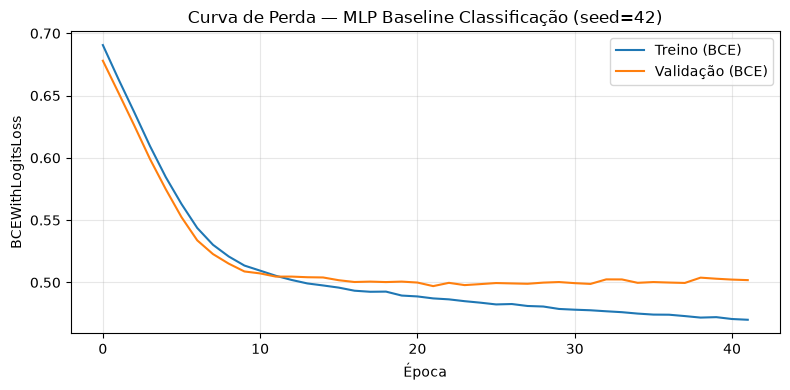

In [28]:
# Gráfico das curvas de perda (Treino vs. Validação)
seed_ref = SEEDS_TREINO[0]
plt.figure(figsize=(8, 4))
plt.plot(historicos_cls[seed_ref]["treino"], label="Treino (BCE)")
plt.plot(historicos_cls[seed_ref]["val"], label="Validação (BCE)")
plt.title(f"Curva de Perda — MLP Baseline Classificação (seed={seed_ref})")
plt.xlabel("Época")
plt.ylabel("BCEWithLogitsLoss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../reports/figures/curva_perda_baseline_cls.png", dpi=150)
plt.show()